# Minimizing the 2-D Ackley Function Using Artificial Bee Colony Optimization

**Course:** Machine Learning  
**Assignment:** Artificial Bee Colony Optimization (ABCO)  
 , , , ,   


## 1. Objective

Find the global minimum of the two-dimensional Ackley function in
$-5 \leq x_1,x_2 \leq 5$. The known solution is $(x_1,x_2)=(0,0)$, where
$f=0$. ABCO is stochastic, so a computed answer can be close to zero
without being exactly zero.


## 2. Ackley Function

$$f(\mathbf{x})=-20\exp\left(-0.2\sqrt{\frac{1}{2}\sum_{j=1}^{2}x_j^2}\right)
-\exp\left(\frac{1}{2}\sum_{j=1}^{2}\cos(2\pi x_j)\right)+20+e.$$

Its repeated local basins make it a useful test of exploration and refinement.
Each **food source** is a real-valued candidate $[x_1,x_2]$.


In [1]:
import io
import math
from dataclasses import dataclass
from time import perf_counter
import numpy as np
from PIL import Image, ImageDraw, ImageFont

np.set_printoptions(precision=8, suppress=True)

def show_chart(image):
    try:
        from IPython.display import display
        display(image)
    except ImportError:
        pass

print("NumPy and Pillow imported successfully.")


NumPy and Pillow imported successfully.


## 3. ABCO Settings

| Setting | Value | Meaning |
|---|---:|---|
| Food sources | 50 | Candidate solutions retained in memory |
| Employed bees | 50 | One searches near each source per cycle |
| Onlooker bees | 50 | Select sources according to quality |
| Dimensions | 2 | $x_1$ and $x_2$ |
| Search bounds | $[-5,5]$ | Applied to both coordinates |
| Maximum cycles | 100 | Same iteration cap as the GA notebook |
| Abandonment limit | 20 | Failed trials before the most stagnant source is replaced |
| Target objective | $10^{-10}$ | Early stop when the best value reaches this tolerance |
| Demonstration seed | 42 | Reproducible main run |

The standard ABC search has employed, onlooker, and scout phases. The
abandonment limit is a chosen setting for this experiment, not a fixed constant
of the algorithm. There are 50 retained candidates and 100 active bees
(50 employed plus 50 onlookers) in a cycle.


In [2]:
@dataclass
class ABCConfig:
    food_sources: int = 50
    dimensions: int = 2
    lower_bound: float = -5.0
    upper_bound: float = 5.0
    max_cycles: int = 100
    abandonment_limit: int = 20
    target_objective: float = 1e-10
    seed: int = 42

config = ABCConfig()
print(config)


ABCConfig(food_sources=50, dimensions=2, lower_bound=-5.0, upper_bound=5.0, max_cycles=100, abandonment_limit=20, target_objective=1e-10, seed=42)


## 4. Optimized Implementation

The employed phase evaluates all 50 candidates in one NumPy batch. Onlookers
can select the same source more than once, so their updates remain sequential;
their random choices are prepared in arrays and each Ackley evaluation uses a
small scalar function. This avoids repeated array creation for one-coordinate
changes while retaining greedy replacement.

For selection, convert the nonnegative Ackley objective to quality with
$q_i=1/(1+f_i)$, then set $p_i=q_i/\sum_k q_k$. A lower objective therefore
gets a higher onlooker selection probability.


In [3]:
TWO_PI = 2.0 * math.pi
INV_SQRT_TWO = 1.0 / math.sqrt(2.0)

def ackley(x):
    """Vectorized Ackley objective for one point, sources, or a grid."""
    x = np.asarray(x, dtype=float)
    x1, x2 = x[..., 0], x[..., 1]
    radius = np.hypot(x1, x2) * INV_SQRT_TWO
    mean_cosine = 0.5 * (np.cos(TWO_PI * x1) + np.cos(TWO_PI * x2))
    return (-20.0 * np.exp(-0.2 * radius)
            - np.exp(mean_cosine) + 20.0 + math.e)

def ackley_xy(x1, x2):
    """Fast scalar objective for a single onlooker neighbor."""
    radius = math.hypot(x1, x2) * INV_SQRT_TWO
    cosine_mean = (math.cos(TWO_PI * x1) + math.cos(TWO_PI * x2)) * 0.5
    return -20.0 * math.exp(-0.2 * radius) - math.exp(cosine_mean) + 20.0 + math.e

def initialize_sources(rng, cfg):
    return rng.uniform(cfg.lower_bound, cfg.upper_bound,
                       size=(cfg.food_sources, cfg.dimensions))

def selection_probabilities(objectives):
    quality = 1.0 / (1.0 + objectives)
    return quality / quality.sum()

print(f"Ackley(0, 0) = {ackley([0, 0]):.16f}")
print(f"Scalar agreement = {abs(ackley_xy(1.2, -0.7)-ackley([1.2, -0.7])):.2e}")


Ackley(0, 0) = 0.0000000000000004
Scalar agreement = 0.00e+00


### Neighbor search and greedy replacement

For source $i$, choose one coordinate $j$, a different source $k$, and a
random coefficient $\phi\in[-1,1]$:

$$v_{ij}=x_{ij}+\phi(x_{ij}-x_{kj}).$$

The candidate coordinate is clipped to $[-5,5]$. Greedy replacement accepts
only a strictly lower Ackley value. Failed attempts increase that source's
trial count. The employed phase uses a snapshot of all current sources to
evaluate its neighbors together; the onlooker phase updates selected sources
one by one because a source can be selected repeatedly.


In [4]:
def employed_phase(sources, objectives, trials, rng, cfg):
    """Evaluate one neighbor per source in one vectorized batch."""
    count = cfg.food_sources
    indices = np.arange(count)
    coordinates = rng.integers(cfg.dimensions, size=count)
    partners = rng.integers(count - 1, size=count)
    partners += partners >= indices  # Every partner differs from its source.
    phi = rng.uniform(-1.0, 1.0, size=count)

    candidates = sources.copy()
    trial_values = (sources[indices, coordinates]
                    + phi * (sources[indices, coordinates]
                             - sources[partners, coordinates]))
    candidates[indices, coordinates] = np.clip(
        trial_values, cfg.lower_bound, cfg.upper_bound)
    candidate_objectives = ackley(candidates)
    improved = candidate_objectives < objectives
    sources[improved] = candidates[improved]
    objectives[improved] = candidate_objectives[improved]
    trials[improved] = 0
    trials[~improved] += 1
    return int(improved.sum())

def onlooker_phase(sources, objectives, trials, rng, cfg):
    """Pre-sample choices, then update repeated selections sequentially."""
    count = cfg.food_sources
    probabilities = selection_probabilities(objectives)
    selected = rng.choice(count, size=count, replace=True, p=probabilities)
    coordinates = rng.integers(cfg.dimensions, size=count)
    partners = rng.integers(count - 1, size=count)
    partners += partners >= selected
    phi = rng.uniform(-1.0, 1.0, size=count)
    successes = 0

    for draw in range(count):
        i = int(selected[draw])
        j = int(coordinates[draw])
        k = int(partners[draw])
        value = sources[i, j] + phi[draw] * (sources[i, j] - sources[k, j])
        value = min(max(float(value), cfg.lower_bound), cfg.upper_bound)
        x1, x2 = sources[i]
        candidate = ackley_xy(value, x2) if j == 0 else ackley_xy(x1, value)
        if candidate < objectives[i]:
            sources[i, j] = value
            objectives[i] = candidate
            trials[i] = 0
            successes += 1
        else:
            trials[i] += 1
    return successes, probabilities, selected

print("Vectorized employed phase and sequential onlooker phase are ready.")


Vectorized employed phase and sequential onlooker phase are ready.


### Scout search and best-ever memory

After employed and onlooker updates, at most one scout replaces the source
with the most failed attempts, provided its count has reached the limit of 20.
The replacement is uniform over the allowed square. The best solution ever
seen is stored separately before this replacement, so an abandoned source
cannot erase a previous result.


In [5]:
def scout_phase(sources, objectives, trials, rng, cfg):
    index = int(np.argmax(trials))
    if trials[index] < cfg.abandonment_limit:
        return False
    sources[index] = rng.uniform(cfg.lower_bound, cfg.upper_bound,
                                 size=cfg.dimensions)
    objectives[index] = ackley_xy(*sources[index])
    trials[index] = 0
    return True

print("Scout phase is ready.")


Scout phase is ready.


In [6]:
def run_abco(cfg, verbose=True):
    rng = np.random.default_rng(cfg.seed)
    sources = initialize_sources(rng, cfg)
    objectives = ackley(sources)
    trials = np.zeros(cfg.food_sources, dtype=int)
    index = int(np.argmin(objectives))
    best_solution = sources[index].copy()
    best_value = float(objectives[index])
    history = {"cycle": [0], "best": [best_value],
               "mean": [float(objectives.mean())],
               "best_x1": [float(best_solution[0])],
               "best_x2": [float(best_solution[1])],
               "scouts": [0]}
    snapshots = [sources.copy()]
    first_onlooker_data = None
    scout_count = 0
    employed_successes = 0
    onlooker_successes = 0
    objective_evaluations = cfg.food_sources

    def remember_best():
        nonlocal best_value, best_solution
        index = int(np.argmin(objectives))
        if objectives[index] < best_value:
            best_value = float(objectives[index])
            best_solution = sources[index].copy()

    stop_reason = "Maximum number of cycles reached"
    for cycle in range(1, cfg.max_cycles + 1):
        employed_successes += employed_phase(sources, objectives, trials, rng, cfg)
        successes, probabilities, selected = onlooker_phase(
            sources, objectives, trials, rng, cfg)
        onlooker_successes += successes
        objective_evaluations += 2 * cfg.food_sources
        if first_onlooker_data is None:
            first_onlooker_data = {
                "cycle": cycle, "probabilities": probabilities.copy(),
                "selected_indices": selected.copy()}

        remember_best()
        scouted = scout_phase(sources, objectives, trials, rng, cfg)
        scout_count += scouted
        objective_evaluations += scouted
        remember_best()

        history["cycle"].append(cycle)
        history["best"].append(best_value)
        history["mean"].append(float(objectives.mean()))
        history["best_x1"].append(float(best_solution[0]))
        history["best_x2"].append(float(best_solution[1]))
        history["scouts"].append(scout_count)
        snapshots.append(sources.copy())

        if best_value <= cfg.target_objective:
            stop_reason = "Target objective reached"
            break

    result = {
        "best_solution": best_solution, "best_value": best_value,
        "cycles_run": history["cycle"][-1], "stop_reason": stop_reason,
        "history": history, "snapshots": snapshots,
        "final_sources": sources.copy(), "final_objectives": objectives.copy(),
        "final_trials": trials.copy(), "first_onlooker_data": first_onlooker_data,
        "scout_count": scout_count, "employed_successes": employed_successes,
        "onlooker_successes": onlooker_successes,
        "objective_evaluations": objective_evaluations,
    }
    if verbose:
        print("Artificial Bee Colony Optimization completed")
        print(f"Stop reason        : {stop_reason}")
        print(f"Cycles run         : {result['cycles_run']}")
        print(f"Best x1            : {best_solution[0]:.12f}")
        print(f"Best x2            : {best_solution[1]:.12f}")
        print(f"Minimum f(x1, x2)  : {best_value:.12e}")
        print(f"Distance from (0,0): {np.linalg.norm(best_solution):.12e}")
        print(f"Scout replacements : {scout_count}")
        print(f"Objective evaluations: {objective_evaluations}")
    return result

print("Optimized ABCO run function is ready.")


Optimized ABCO run function is ready.


## 5. Run the Algorithm

Seed 42 makes the demonstration reproducible. The final value is generated by
the optimized implementation above; it can differ from the earlier notebook
because employed neighbors are evaluated together from one source snapshot.


In [7]:
start = perf_counter()
result = run_abco(config)
elapsed_seconds = perf_counter() - start
print(f"Elapsed on this machine: {elapsed_seconds:.3f} s")


Artificial Bee Colony Optimization completed
Stop reason        : Target objective reached
Cycles run         : 79
Best x1            : 0.000000000001
Best x2            : 0.000000000027
Minimum f(x1, x2)  : 7.559508574673e-11
Distance from (0,0): 2.672700326224e-11
Scout replacements : 3
Objective evaluations: 7953
Elapsed on this machine: 0.022 s


## 6. Onlooker Selection

The chart shows the ten highest selection probabilities after the first
employed phase. The left bars are probability; the right bars count how often
the 50 onlookers selected each source. The counts are random and need not rank
exactly like the probabilities in one cycle.


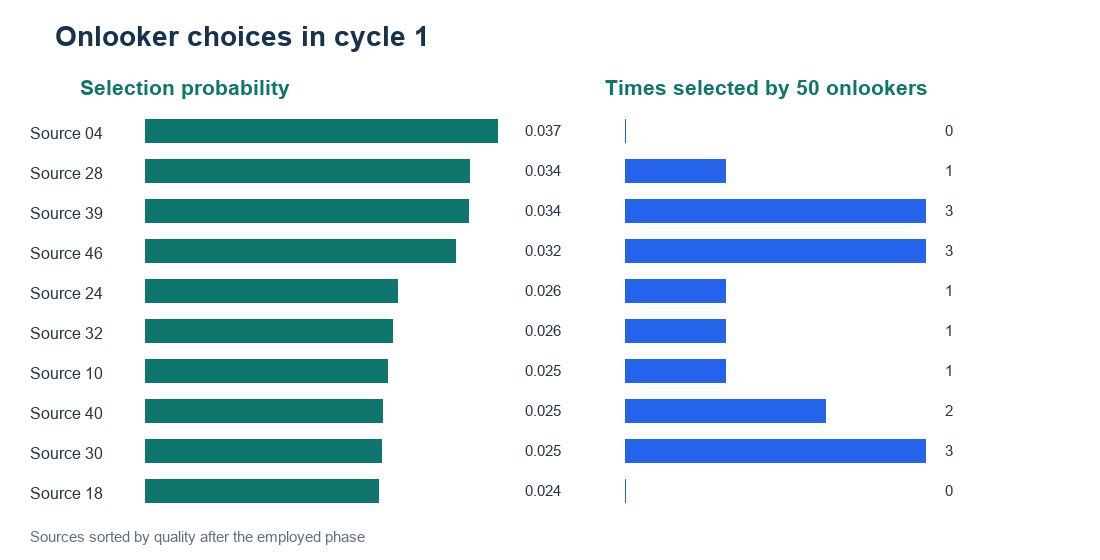

In [8]:
def _font(size, bold=False):
    names = (["C:/Windows/Fonts/arialbd.ttf", "DejaVuSans-Bold.ttf"] if bold
             else ["C:/Windows/Fonts/arial.ttf", "DejaVuSans.ttf"])
    for name in names:
        try:
            return ImageFont.truetype(name, size)
        except OSError:
            pass
    return ImageFont.load_default()

def _base_plot(title, width=1000, height=560):
    image = Image.new("RGB", (width, height), "white")
    draw = ImageDraw.Draw(image)
    draw.text((55, 20), title, fill="#17324D", font=_font(28, True))
    return image, draw

def selection_chart(data):
    probabilities = data["probabilities"]
    counts = np.bincount(data["selected_indices"],
                         minlength=len(probabilities))
    selected = np.argsort(probabilities)[-10:][::-1]
    image, draw = _base_plot("Onlooker choices in cycle 1", 1100, 560)
    draw.text((80, 75), "Selection probability", fill="#0F766E", font=_font(21, True))
    draw.text((605, 75), "Times selected by 50 onlookers", fill="#0F766E", font=_font(21, True))
    pmax = max(probabilities[selected]) * 1.05
    cmax = max(1, int(max(counts[selected])))
    for rank, index in enumerate(selected):
        y = 119 + rank * 40
        draw.text((30, y + 5), f"Source {index:02d}", fill="#243447", font=_font(16))
        draw.rectangle((145, y, 145 + int(370 * probabilities[index] / pmax), y + 23),
                       fill="#0F766E")
        draw.text((525, y + 3), f"{probabilities[index]:.3f}", fill="#243447", font=_font(15))
        draw.rectangle((625, y, 625 + int(300 * counts[index] / cmax), y + 23),
                       fill="#2563EB")
        draw.text((945, y + 3), str(counts[index]), fill="#243447", font=_font(15))
    draw.text((30, 528), "Sources sorted by quality after the employed phase",
              fill="#5E7184", font=_font(15))
    return image

__image__ = selection_chart(result["first_onlooker_data"])
show_chart(__image__)


In [9]:
selected = result["first_onlooker_data"]["selected_indices"]
print("Selected source indices in cycle 1:")
print(selected)
print("Unique sources selected:", len(np.unique(selected)))


Selected source indices in cycle 1:
[39 48 26  7  0 12  6 34  6 26 35 29 10 40 36 37  6  6 46 21 16 25 33 47
 15 46  1 28 32  5  7 22 47 30 46 40 24 39  0  5 41 39 12 27 30 43 30 21
 19 22]
Unique sources selected: 32


## 7. Convergence Analysis

The blue line records the best **ever** objective and cannot increase. The
orange line is the mean objective of current sources. Scout replacement can
temporarily raise the mean while introducing a new location. The logarithmic
axis reveals improvements near zero.


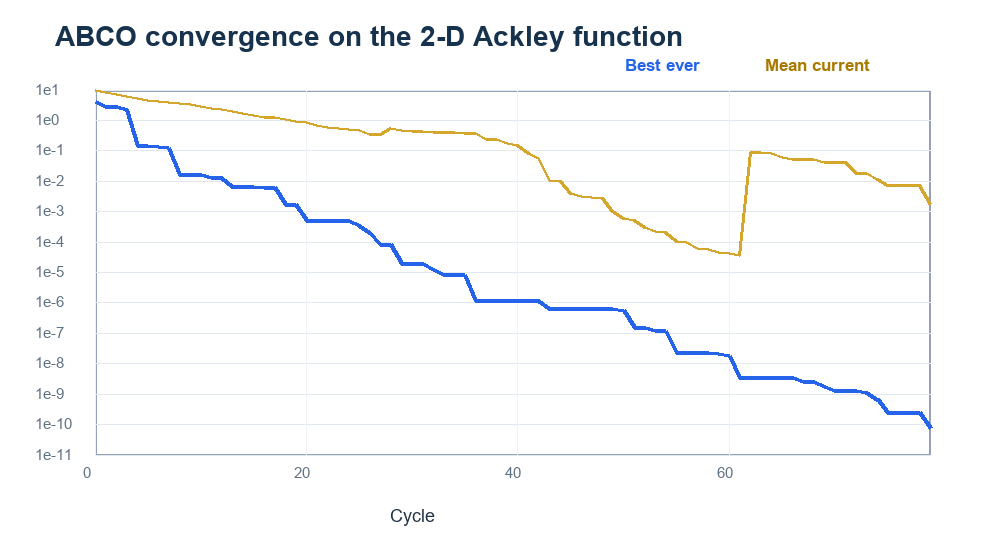

In [10]:
def convergence_chart(history):
    image, draw = _base_plot("ABCO convergence on the 2-D Ackley function")
    left, top, right, bottom = 95, 90, 930, 455
    draw.rectangle((left, top, right, bottom), outline="#94A3B8", width=2)
    cycles = np.asarray(history["cycle"])
    best = np.asarray(history["best"])
    mean = np.asarray(history["mean"])
    ymin = 10.0 ** np.floor(np.log10(max(best.min(), 1e-16)))
    ymax = 10.0 ** np.ceil(np.log10(max(mean.max(), best.max())))
    lo, hi = np.log10(ymin), np.log10(ymax)
    for exponent in range(int(lo), int(hi) + 1):
        y = int(bottom - (exponent - lo) / (hi - lo) * (bottom - top))
        draw.line((left, y, right, y), fill="#E2E8F0", width=1)
        draw.text((35, y - 9), f"1e{exponent}", fill="#5E7184", font=_font(15))
    for tick in range(0, int(cycles[-1]) + 1, 20):
        x = int(left + tick / cycles[-1] * (right - left))
        draw.line((x, top, x, bottom), fill="#EDF2F7", width=1)
        draw.text((x - 12, bottom + 9), str(tick), fill="#5E7184", font=_font(15))
    def points(values):
        logs = np.log10(np.maximum(values, ymin))
        return [(int(left + c / cycles[-1] * (right - left)),
                 int(bottom - (v - lo) / (hi - lo) * (bottom - top)))
                for c, v in zip(cycles, logs)]
    draw.line(points(mean), fill="#D4A72C", width=3)
    draw.line(points(best), fill="#2563EB", width=4)
    draw.text((390, 505), "Cycle", fill="#243447", font=_font(18))
    draw.text((625, 55), "Best ever", fill="#2563EB", font=_font(17, True))
    draw.text((765, 55), "Mean current", fill="#A97900", font=_font(17, True))
    return image

__image__ = convergence_chart(result["history"])
show_chart(__image__)


## 8. Search-Space Visualization

The color field is the Ackley objective over the allowed square. The white
path links locations where the best-ever solution improved. The red cross is
the known optimum at $(0,0)$; the cyan circle marks the final solution.


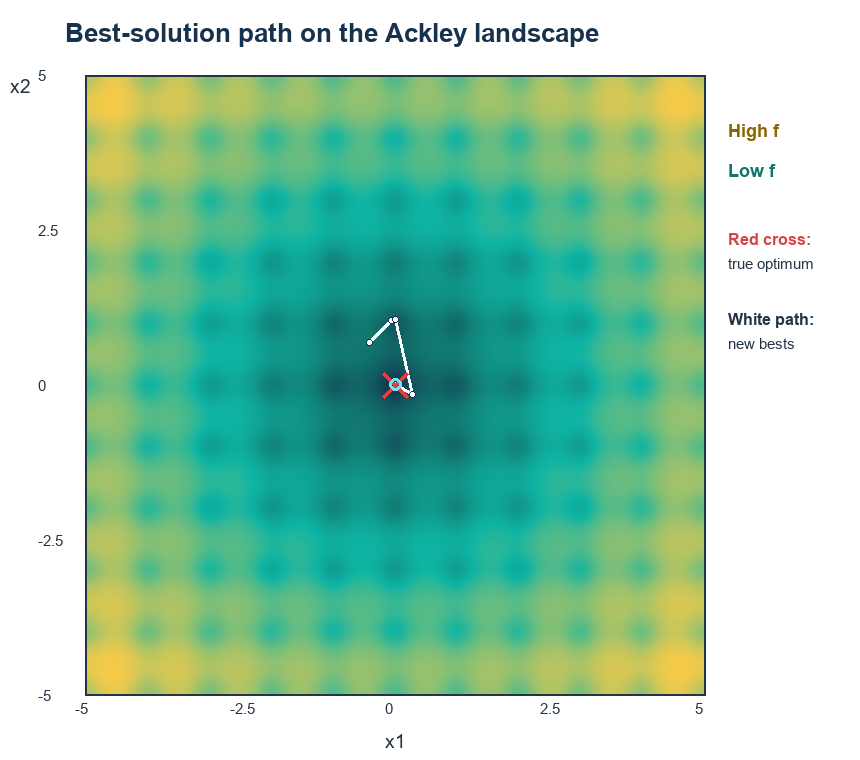

In [11]:
def landscape_chart(history, final_solution, cfg):
    grid = np.linspace(cfg.lower_bound, cfg.upper_bound, 350)
    X1, X2 = np.meshgrid(grid, grid)
    Z = ackley(np.stack((X1, X2), axis=-1))
    scaled = (Z - Z.min()) / (Z.max() - Z.min())
    stops = np.array([0.0, 0.3, 0.6, 1.0])
    red = np.interp(scaled, stops, [17, 18, 15, 247])
    green = np.interp(scaled, stops, [50, 118, 180, 203])
    blue = np.interp(scaled, stops, [77, 110, 164, 73])
    heat = Image.fromarray(np.stack((red, green, blue), axis=-1).astype("uint8"), "RGB")
    heat = heat.transpose(Image.Transpose.FLIP_TOP_BOTTOM).resize((620, 620))
    image = Image.new("RGB", (860, 760), "white")
    draw = ImageDraw.Draw(image)
    draw.text((65, 18), "Best-solution path on the Ackley landscape",
              fill="#17324D", font=_font(26, True))
    image.paste(heat, (85, 75))
    draw.rectangle((85, 75, 705, 695), outline="#243447", width=2)
    def pixel(point):
        x = 85 + (point[0] - cfg.lower_bound) / (cfg.upper_bound - cfg.lower_bound) * 620
        y = 695 - (point[1] - cfg.lower_bound) / (cfg.upper_bound - cfg.lower_bound) * 620
        return int(x), int(y)
    path = np.column_stack((history["best_x1"], history["best_x2"]))
    changed = np.r_[True, np.any(np.diff(path, axis=0) != 0, axis=1)]
    path = path[changed]
    if len(path) > 1:
        draw.line([pixel(point) for point in path], fill="white", width=3)
    for point in path:
        x, y = pixel(point)
        draw.ellipse((x-3, y-3, x+3, y+3), fill="white", outline="#17324D")
    x, y = pixel((0, 0))
    draw.line((x-12, y-12, x+12, y+12), fill="#D64545", width=4)
    draw.line((x-12, y+12, x+12, y-12), fill="#D64545", width=4)
    x, y = pixel(final_solution)
    draw.ellipse((x-6, y-6, x+6, y+6), outline="#67E8F9", width=3)
    for value in [-5, -2.5, 0, 2.5, 5]:
        x = int(85 + (value + 5) / 10 * 620)
        y = int(695 - (value + 5) / 10 * 620)
        draw.text((x-10, 700), str(value), fill="#243447", font=_font(15))
        draw.text((38, y-8), str(value), fill="#243447", font=_font(15))
    draw.text((385, 730), "x1", fill="#243447", font=_font(19))
    draw.text((10, 75), "x2", fill="#243447", font=_font(19))
    draw.text((728, 120), "High f", fill="#8A6500", font=_font(18, True))
    draw.text((728, 160), "Low f", fill="#0F766E", font=_font(18, True))
    draw.text((728, 230), "Red cross:", fill="#D64545", font=_font(16, True))
    draw.text((728, 255), "true optimum", fill="#243447", font=_font(15))
    draw.text((728, 310), "White path:", fill="#243447", font=_font(16, True))
    draw.text((728, 335), "new bests", fill="#243447", font=_font(15))
    return image

__image__ = landscape_chart(result["history"], result["best_solution"], config)
show_chart(__image__)


## 9. Animated Search Simulation

The animation shows all 50 current food sources on the Ackley landscape as
the algorithm runs. The red cross marks the best solution found so far;
its reported objective decreases as better sources appear. The GIF loops
automatically here and in desktop PowerPoint Slide Show. It is an animation of
the recorded seeded run, not a new run triggered by the slide.


Animated simulation: 80 recorded cycles


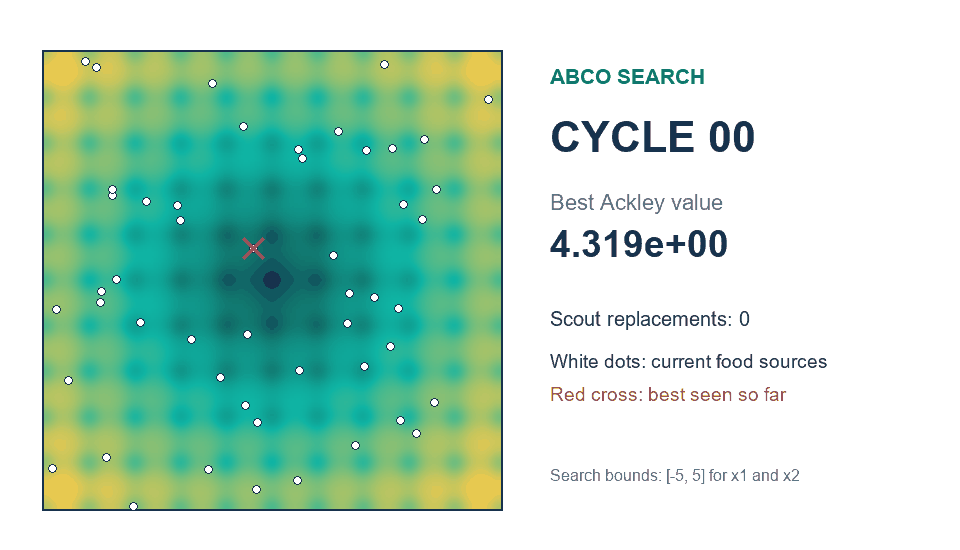

In [12]:
def simulation_gif(result, cfg):
    grid = np.linspace(cfg.lower_bound, cfg.upper_bound, 250)
    X1, X2 = np.meshgrid(grid, grid)
    Z = ackley(np.stack((X1, X2), axis=-1))
    scaled = (Z - Z.min()) / (Z.max() - Z.min())
    stops = [0.0, 0.3, 0.6, 1.0]
    rgb = np.stack([
        np.interp(scaled, stops, [17, 18, 15, 247]),
        np.interp(scaled, stops, [50, 118, 180, 203]),
        np.interp(scaled, stops, [77, 110, 164, 73]),
    ], axis=-1).astype("uint8")
    background = Image.fromarray(rgb, "RGB")
    background = background.transpose(Image.Transpose.FLIP_TOP_BOTTOM)
    background = background.resize((460, 460))
    snapshots = result["snapshots"]
    history = result["history"]
    frame_indices = list(range(0, len(snapshots), 2))
    if frame_indices[-1] != len(snapshots) - 1:
        frame_indices.append(len(snapshots) - 1)

    def pixel(point):
        x = 42 + (point[0] - cfg.lower_bound) / 10.0 * 460
        y = 510 - (point[1] - cfg.lower_bound) / 10.0 * 460
        return int(x), int(y)

    frames = []
    for t in frame_indices:
        frame = Image.new("RGB", (960, 550), "white")
        draw = ImageDraw.Draw(frame)
        frame.paste(background, (42, 50))
        draw.rectangle((42, 50, 502, 510), outline="#17324D", width=2)
        for point in snapshots[t]:
            x, y = pixel(point)
            draw.ellipse((x-4, y-4, x+4, y+4),
                         fill="#FFFFFF", outline="#17324D", width=1)
        best_point = (history["best_x1"][t], history["best_x2"][t])
        x, y = pixel(best_point)
        draw.line((x-10, y-10, x+10, y+10), fill="#D64545", width=4)
        draw.line((x-10, y+10, x+10, y-10), fill="#D64545", width=4)

        draw.text((550, 64), "ABCO SEARCH", fill="#0F766E", font=_font(21, True))
        draw.text((550, 113), f"CYCLE {t:02d}", fill="#17324D", font=_font(43, True))
        draw.text((550, 190), "Best Ackley value", fill="#5E7184", font=_font(22))
        draw.text((550, 223), f"{history['best'][t]:.3e}",
                  fill="#17324D", font=_font(37, True))
        draw.text((550, 307), f"Scout replacements: {history['scouts'][t]}",
                  fill="#243447", font=_font(20))
        draw.text((550, 350), "White dots: current food sources",
                  fill="#243447", font=_font(19))
        draw.text((550, 383), "Red cross: best seen so far",
                  fill="#D64545", font=_font(19))
        draw.text((550, 466), "Search bounds: [-5, 5] for x1 and x2",
                  fill="#5E7184", font=_font(16))
        frames.append(frame.convert("P", palette=Image.Palette.ADAPTIVE, colors=128))

    buffer = io.BytesIO()
    frames[0].save(buffer, format="GIF", save_all=True,
                   append_images=frames[1:], duration=180,
                   loop=0, optimize=True, disposal=2)
    return buffer.getvalue()

__gif_bytes__ = simulation_gif(result, config)
try:
    from IPython.display import display, Image as JupyterImage
    display(JupyterImage(data=__gif_bytes__))
except ImportError:
    pass
print(f"Animated simulation: {len(result['snapshots'])} recorded cycles")


## 10. Reliability Across Multiple Runs

One seed cannot establish reliability. Repeat the optimized experiment for ten
independent seeds (100 to 109). Report the best and mean objective, spread, and
the number of runs meeting the target tolerance.


In [13]:
number_of_runs = 10
run_values = []
run_distances = []
run_cycles = []
print(f"{'Run':>4} {'Seed':>6} {'Best f(x)':>15} {'Distance':>15} {'Cycles':>7}")
print("-" * 54)
for run_number in range(number_of_runs):
    run_cfg = ABCConfig(**vars(config))
    run_cfg.seed = 100 + run_number
    one_result = run_abco(run_cfg, verbose=False)
    run_values.append(one_result["best_value"])
    run_distances.append(np.linalg.norm(one_result["best_solution"]))
    run_cycles.append(one_result["cycles_run"])
    print(f"{run_number+1:>4} {run_cfg.seed:>6} {run_values[-1]:>15.6e} "
          f"{run_distances[-1]:>15.6e} {run_cycles[-1]:>7}")
run_values = np.asarray(run_values)
run_distances = np.asarray(run_distances)
run_cycles = np.asarray(run_cycles)
print("\nSummary over 10 independent runs")
print(f"Best objective value  : {run_values.min():.6e}")
print(f"Mean objective value  : {run_values.mean():.6e}")
print(f"Median objective value: {np.median(run_values):.6e}")
print(f"Standard deviation    : {run_values.std(ddof=1):.6e}")
print(f"Target met            : {np.count_nonzero(run_values <= config.target_objective)}/10")


 Run   Seed       Best f(x)        Distance  Cycles
------------------------------------------------------
   1    100    6.591039e-11    2.330347e-11      78
   2    101    7.142775e-11    2.525366e-11      82
   3    102    2.932454e-11    1.036772e-11      80
   4    103    6.469536e-11    2.287343e-11      81
   5    104    3.567679e-11    1.261396e-11      79
   6    105    6.986811e-11    2.470175e-11      81
   7    106    7.421308e-11    2.623807e-11      80
   8    107    7.527179e-11    2.661237e-11      78
   9    108    7.841949e-11    2.772579e-11      85
  10    109    9.410828e-11    3.327234e-11      72

Summary over 10 independent runs
Best objective value  : 2.932454e-11
Mean objective value  : 6.589156e-11
Median objective value: 7.064793e-11
Standard deviation    : 1.946033e-11
Target met            : 10/10


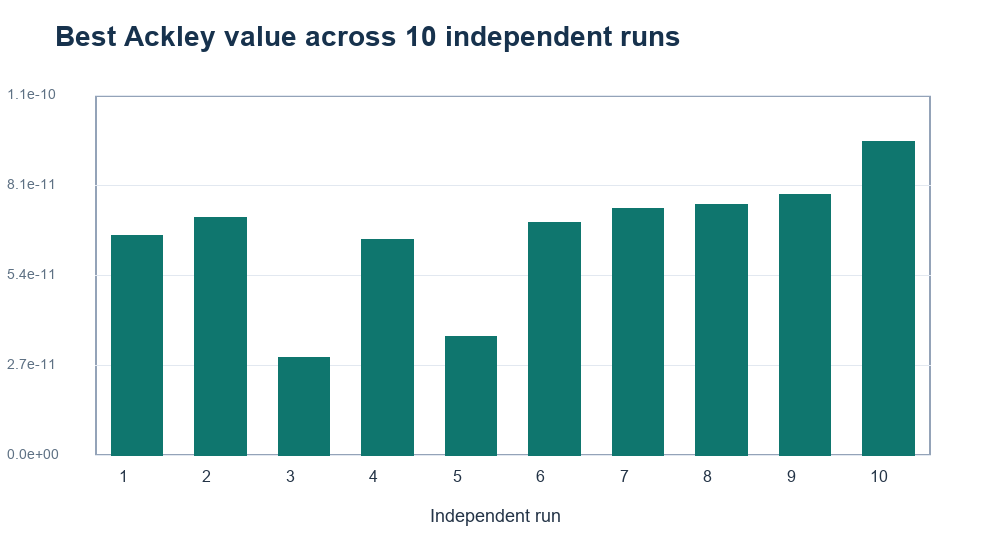

In [14]:
def reliability_chart(values):
    image, draw = _base_plot("Best Ackley value across 10 independent runs")
    left, top, right, bottom = 95, 95, 930, 455
    draw.rectangle((left, top, right, bottom), outline="#94A3B8", width=2)
    max_value = float(np.max(values)) * 1.15
    for tick in range(5):
        y = int(bottom - tick / 4 * (bottom - top))
        draw.line((left, y, right, y), fill="#E2E8F0", width=1)
        draw.text((7, y-9), f"{max_value*tick/4:.1e}",
                  fill="#5E7184", font=_font(14))
    width = (right - left) / len(values)
    for index, value in enumerate(values):
        x0 = int(left + index * width + 16)
        x1 = int(left + (index+1) * width - 16)
        y = int(bottom - value / max_value * (bottom - top))
        draw.rectangle((x0, y, x1, bottom), fill="#0F766E")
        draw.text((x0+8, bottom+12), str(index+1), fill="#243447", font=_font(16))
    draw.text((430, 505), "Independent run", fill="#243447", font=_font(18))
    return image

__image__ = reliability_chart(run_values)
show_chart(__image__)


## 11. Automatic Correctness Checks

The checks verify the known optimum, agreement between scalar and vectorized
objective functions, source count and bounds, finite values, normalized
selection probabilities, non-increasing best-ever history, and the objective
evaluation count.


In [15]:
assert np.isclose(ackley([0, 0]), 0.0, atol=1e-12)
points = np.array([[0.0, 0.0], [1.2, -0.7], [-3.1, 4.2]])
assert np.allclose(ackley(points), [ackley_xy(*p) for p in points], atol=1e-12)
assert result["final_sources"].shape == (config.food_sources, config.dimensions)
assert np.all(result["final_sources"] >= config.lower_bound)
assert np.all(result["final_sources"] <= config.upper_bound)
assert np.all(np.isfinite(result["final_objectives"]))
assert np.all(np.diff(result["history"]["best"]) <= 1e-12)
assert np.isclose(ackley(result["best_solution"]), result["best_value"], atol=1e-12)
probabilities = result["first_onlooker_data"]["probabilities"]
assert np.all(probabilities >= 0) and np.isclose(probabilities.sum(), 1.0)
expected_evaluations = (config.food_sources
                        + 2 * config.food_sources * result["cycles_run"]
                        + result["scout_count"])
assert result["objective_evaluations"] == expected_evaluations
print("All correctness checks passed.")


All correctness checks passed.


## 12. Conclusion

With 50 sources and a maximum of 100 cycles, the optimized ABCO code found a
point close to the known optimum $(0,0)$. Batch employed-bee evaluation avoids
50 separate NumPy objective calls per cycle. Pre-sampled random choices and a
scalar two-coordinate objective make repeated onlooker updates cheaper. Scout
replacement preserves exploration, while separate best-ever memory protects
the best result.

The ten-seed experiment describes reliability for this 2-D problem and these
settings; it is not a claim about every optimization task.

**Algorithm reference:** Karaboga, D. and Basturk, B. (2007), “A powerful and
efficient algorithm for numerical function optimization: artificial bee colony
(ABC) algorithm,” *Journal of Global Optimization*, 39, 459–471.
https://doi.org/10.1007/s10898-007-9149-x  
**Assignment reference:** the supplied `assignment.ipynb` and its 2-D Ackley
problem statement.
